In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [2]:
from classes import *
from functions import *
from utils import *
from metrics import *
import seaborn as sns
import statsmodels.tsa as sm
import statsmodels.api as sma
import matplotlib.pyplot as plt
import pickle
import warnings
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)

## 0. Le modèle et ses grandeurs


Le modèle s'écrit :

\begin{align}
&\epsilon_t = \sigma_t\eta_t\\
&\sigma_t^2 = \omega(\Delta_t)+\sum_{i=1}^q\alpha_i(\Delta_t)\epsilon_{t-i}^2{+\sum_{j=1}^k\mu_j(\Delta_t)|x_{j,t-1}|}\\
&P(\Delta_{t}=j|\Delta_{t-1}=i,\mathcal{O}_t) = P(i,j){\times\frac{\exp(\beta_{ij}'X_{t-1})}{\sum_{l=1}^dp_0(i,l)\exp(\beta_{il}'X_{t-1})}}
\end{align}

Avec:
- $\Delta_t$ la chaîne de markov, qui comprend $d$ états
- $\epsilon_t$ le processus (correspond aux rendements qu'on veut modéliser)
- $X_t$ la (ou les) variable(s) exogène(s)

Les paramètres sont:
- $\alpha$, qui est de shape $(q*d)
- $\omega$, qui est de shape $d$
- exogen_additive et exogen_transition (qui correspondent respectivement aux exogènes à mettre dans les deux équations du modèle, même si ils ne sont pas séparés dans l'écriture initiale), additive correspond à l'équation 2 et transition à l'équation 3,\
les deux sont de shape $(n*k)$, avec $k$ le nombre d'exogènes, et $n$ la taile du sample. plus précisément exogen_additive est de shape $(n*k_{add})$, et exogen_transition de shape $(n*k_{trans})$. mais pour l'instant je n'ai jamais distingué les deux $k$
shape
- $\mu$, qui est de shape $(k_{add},d)$
- $\beta$ qui est de shape $(d,d,k_{trans})
- $P$ qui est de shape $(d,d)$

# 1. La classe MS_ARCH
Input : un dictionnaire, qui doit contenir:
- $\alpha$
- $P$
- $\pi_0$, les probabilités initiales de la chaîne de markov, pas important non plus

et (optionnels);
- exogen_additive et exogen_transition
- $\beta$ (si il y a exogen transition)
- $\mu$ (si il y a exogen additive)
- 'transition_f', ne t'en occupe pas, pas important

Tu peux ensuite utiliser model.simulate pour générer un échantillon via les paramètres que tu as spécifié. dans l'exemple np.random.seed force la séquence aléatoire à être la même\
 (utile pour reproduire les résultats), tu peux la retirer si tu veux des résultats différents à chaque fois.\
 Tu peux ensuite trouver les résultats dans les attributs de model, le plus important étant ta série de $\epsilon$ générée, que tu as via model.eps


In [3]:
np.random.seed(5)
sample_size = 10000

true_params =  {'alpha':np.array([[0.2,0.4],[0.8,0.1]]),\
               'P': np.array([[0.98,0.02],[0.01,0.99]]),\
               'omega':np.array([0.2,0.8]),\
               #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)).reshape(-1,1),\
               'beta' : np.array([[[-0.1,0],[0.1,0]],[[0.5,0],[-0.5,0]]]).reshape(2,2,2),\
               'mu' : np.array([[0.4,0],[0,0.5]]),\
               'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
               'exogen_transition' : AR([0.9,0.08],length=sample_size*2).reshape(sample_size,2),\
               'transition_f' : 'soft-exp',\
               #'seed' : 5,\
                "pi_0":np.array([0.5,0.5])}

[-0.04721937  0.89346525 -0.61211965 ... -3.17191532 -0.59211372
  4.28864783]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

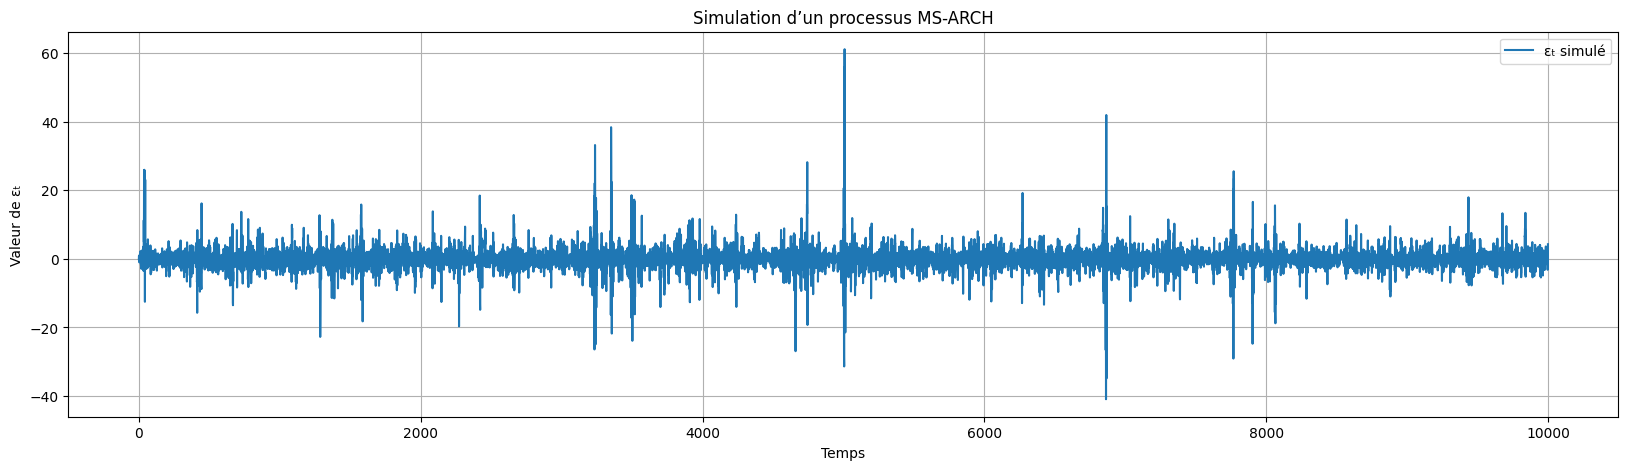

In [12]:
model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)
#true_params['log-likelihood'] = compute_log_likelihood(model.eps,true_params)
print(model.eps)
print(model.states)
states = np.array(model.states)
print("Régime 0 :", np.sum(states == 0))
print("Régime 1 :", np.sum(states == 1))

plt.figure(figsize=(20, 5))
plt.plot(model.eps, label="εₜ simulé")
plt.title("Simulation d’un processus MS-ARCH")
plt.xlabel("Temps")
plt.ylabel("Valeur de εₜ")
plt.legend()
plt.grid(True)
plt.show()




# 2. La fonction de calibration MS_EM_algorithm
Input : 
1. ta série (epsilon), un array d'une dimension

2. un dictionnaire de paramètres initiaux, qui doit contenir (same que pour le 1. + le $\lambda$):
- $\alpha$
- $P$
- $\pi_0$, les probabilités initiales de la chaîne de markov, pas important non plus

et (optionnels);
- exogen_additive et exogen_transition
- $\beta$ (si il y a exogen transition)
- $\mu$ (si il y a exogen additive)
- 'transition_f', ne t'en occupe pas, pas important
- $\lambda$ le paramètre de pénalisation correspondant à la méthode LASSO, si tu ne le spécifie pas il vaut $0$ par défaut, donc pas besoin de t'en occuper sauf si tu veux utiliser la méthode LASSO

3. le nombre d'itérations (niter), souvent niter=200 suffit, voire moins, mais ça m'arrive de prendre niter=1000 pour être tranquille.

Tu peux ensuite utiliser MS_EM_algorithm pour calibrer ton modèle, le résultat est un dictionnaire, chaque clé correspond à une itération, donc ton résultat final correspond à result[niter], result[0] comprend les conditions initiales. Les paramètres n'étant pas update\
(exogen_transition, exogen_additive, lambda) ne sont pas dans les result[i] sauf dans result[0].

In [14]:
initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.3,0.7]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0],[0,0]]),\
                    'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'transition_f' : 'soft-exp',\
                    'beta' : np.zeros((2,2,2)),\
                    'beta_constraint' : 'general',\
                    'mu' : np.array([[0,0],[0,0]]),
                    'lambda' : 0\
                         }

results = MS_EM_algorithm(model.eps,initial_params,niter=10)

mu of dimension 2: will depend on delta


  0%|          | 0/10 [00:00<?, ?it/s]/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
100%|██████████| 10/10 [01:12<00:00,  7.26s/it]


In [18]:

print(results[9])

{'P': array([[0.5, 0.5],
       [0.5, 0.5]]), 'beta': array([[[0., 0.],
        [0., 0.]],

       [[0., 0.],
        [0., 0.]]]), 'omega': array([0.3, 0.7]), 'alpha': array([[0., 0.],
       [0., 0.]]), 'mu': array([[0., 0.],
       [0., 0.]]), 'pi_0': array([nan, nan]), 'log-likelihood': nan}


# 3. La fonction de storing de tous les résultats calibrate_and_store

Cette fonction prend en entrée des données, et des colonnes qui vont être les targets (les $\epsilon$) et les indicators (les exogènes), elle apply un preprocessing si demandé, et calibre ensuite toutes les combinaisons de target,indicator\
toutes les inputs sont expliquées dans le détail de la fonction, et c'est la fonction que tu utiliseras probablement le plus. Ci-dessous un exemple de preprocessing_dict.

In [ ]:
# Dictionnaire des règles de prétraitement
preprocessing_dict = {
    # Targets - rendements log
    'SPX Index': ['log', 'diff'],# 'standardize'],
    'CAC Index': ['log', 'diff'],# 'standardize'],
    'DAX Index': ['log', 'diff'],# 'standardize'],
    'SXXP Index': ['log', 'diff'],# 'standardize'],
    'SX5E Index': ['log', 'diff'],# 'standardize'],
    'NKY Index': ['log', 'diff'],# 'standardize'],
    'RTY Index': ['log', 'diff'],# 'standardize'],
    'NDX Index': ['log', 'diff'],# 'standardize'],
    
    # Commodities
    'CO1 Comdty': ['log', 'diff', 'standardize'],
    'XAU Curncy': ['log', 'diff', 'standardize'],
    
    # Interest rates (niveau, pas de diff)
    'USGG10YR Index': ['diff', 'standardize'],
    'USGG2YR Index': ['diff', 'standardize'],
    'GTDEM10Y Govt': ['diff', 'standardize'],
    'GTDEM2Y Govt': ['diff', 'standardize'],

    # Credit spreads
    'CDX IG CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'CDX HY CDSI GEN 5Y SPRD Corp': ['diff', 'standardize'],
    'ITRX XOVER CDSI GEN 5Y Corp': ['diff', 'standardize'],
    'ITRX EUR CDSI GEN 5Y Corp': ['diff', 'standardize'],

    # Volatility indices
    'VIX Index': ['log', 'diff', 'standardize'],
    'VIX9D Index': ['log', 'diff', 'standardize'],
    'VIX3M Index': ['log', 'diff', 'standardize'],
    'VIX6M Index': ['log', 'diff', 'standardize'],
    'V2X Index': ['log', 'diff', 'standardize'],

    # Economic surprise indices
    'CESIUSD Index': ['diff','standardize'],
    'CESIEUR Index': ['diff','standardize'],
    'CESICNY Index': ['diff','standardize'],
    'CESIGBP Index': ['diff','standardize'],

    # MOVE Index
    'MOVE Index': ['log', 'diff', 'standardize'],
    'MOVE3M Index': ['log', 'diff', 'standardize'],
    'SMOVEU1M Index': ['log', 'diff', 'standardize'],
    'SMOVEU3M Index': ['log', 'diff', 'standardize'],

    # News & Sentiment
    'SFFRNEWS Index': ['standardize'],
    'RCHSINDX Index': ['standardize'],

    # Crypto
    'XBTUSD Curncy': ['log', 'diff', 'standardize'],

    # FX (à ne pas prétraiter — utilisés comme multiplicateurs)
    'EURUSD Curncy': ['log', 'diff', 'standardize'],
    'USDJPY Curncy': ['log', 'diff', 'standardize'],
    'USDGBP Curncy': ['log', 'diff', 'standardize'],
    'USDCHF Curncy': ['log', 'diff', 'standardize'],
    'USDCNY Curncy': ['log', 'diff', 'standardize'],
}

In [10]:
def calibrate_and_store(
    data,                     # DataFrame contenant la cible et les variables exogènes
    targets,                  # Liste des noms de séries cibles (colonnes de data)
    indicators,               # Liste de listes de noms de colonnes exogènes
    niter_HMM=1000,           # Nb d’itérations pour initialisation type HMM
    niter_MS=1000,            # Nb d’itérations pour estimation sans exogènes
    niter_X=200,              # Nb d’itérations pour estimation avec exogènes
    d=2, q=1,                 # Ordres du MS-ARCH
    start=None, end=None,     # Dates pour restreindre les données exogènes
    additive_method='absolute', # Méthode de transformation des exogènes (|X| ou X²)
    folder='RealDataResults', # Dossier de sauvegarde
    preprocessing_dict=None   # Dictionnaire de prétraitement éventuel
):

    
    folder = 'Results/' + folder
    store = defaultdict(lambda: {})

    os.makedirs(folder, exist_ok=True)

    if preprocessing_dict is not None:
        data = apply_preprocessing(data, preprocessing_dict)
        with open(f"{folder}//preprocessing_dict.pkl", "wb") as f:
            pickle.dump(preprocessing_dict, f)
    with open(f"{folder}//preprocessed_data.pkl", "wb") as f:
        pickle.dump(data, f)

    if np.ndim(indicators) != 2:
        raise ValueError('Indicators should be a list of lists')
    
    for target in tqdm(targets):
        # Étape 1 : prétraitement eps seul
        eps_series = data[target].dropna()
        valid_eps_dates = eps_series.index
        eps = np.array(eps_series, dtype='float64')

        # Conditions initiales (indépendantes des indicateurs)
        initial_params = get_initial_conditions(eps, {}, d, q, niter=niter_HMM)
        constrained_result = MS_EM_algorithm(eps, initial_params, niter=niter_MS)
        new_initial_params = deepcopy(constrained_result[niter_MS])

        store[target]['No Exogenous'] = {
            'eps': deepcopy(eps),
            'dates' : valid_eps_dates,
            'target': target,
            'indicator': 'No Exogenous',
            'initial_params': deepcopy(new_initial_params),
            'result': deepcopy(constrained_result),
            'final_result': deepcopy(new_initial_params),
            'states sequence': viterbi_continuous(eps, new_initial_params)
        }
        store[target]['No Exogenous']['final_result']['mean log-likelihood'] = new_initial_params['log-likelihood']/len(valid_eps_dates)
        
        with open(f"{folder}//{target}+No Exogenous_results"+".pkl", "wb") as f:
            pickle.dump(store[target]['No Exogenous'], f)

        for indicator in tqdm(indicators):
            path = '+'.join(indicator)
            
            # Étape 2 : préparation des indicateurs restreints aux dates valides d'eps
            indicator_df = data[indicator].loc[valid_eps_dates].copy()

            # Drop uniquement sur indicateurs
            indicator_df = indicator_df.dropna()
            joint_dates = indicator_df.index

            # Appliquer filtre start/end
            if start is not None:
                joint_dates = joint_dates[joint_dates >= pd.to_datetime(start)]
            if end is not None:
                joint_dates = joint_dates[joint_dates <= pd.to_datetime(end)]

            if joint_dates.empty:
                print(f"Skipped {target}+{path}: no valid joint dates.")
                continue

            # Final alignement
            eps_aligned = eps_series.loc[joint_dates]
            X = indicator_df.loc[joint_dates].values
            eps_arr = np.array(eps_aligned, dtype='float64')

            k = X.shape[1]
            
            # Préparation des paramètres et estimation
            params = deepcopy(new_initial_params)
            params['exogen_transition'] = deepcopy(X)
            if additive_method == 'absolute':
                additive = np.abs(X)
            elif additive_method == 'square':
                additive = np.square(X)
            else:
                raise ValueError("additive_method must be either 'absolute' or 'square'")
            params['exogen_additive'] = deepcopy(additive)

            params['mu'] = np.zeros((k, d))
            params['beta'] = np.zeros((d, d, k))

            result = MS_EM_algorithm(eps_arr, params, niter=niter_X)

            store[target][path] = {
                'data': deepcopy(X),
                'eps': deepcopy(eps_arr),
                'dates': joint_dates,
                'target': target,
                'indicator': path,
                'initial_params': deepcopy(params),
                'result': deepcopy(result),
                #'pi': deepcopy(pi),
                'final_result': result[niter_X],
                'states sequence': viterbi_continuous(eps_arr, result[niter_X])
            }

            store[target][path]['final_result']['exogen_transition'] = deepcopy(X)
            store[target][path]['final_result']['exogen_additive'] = deepcopy(additive)
            store[target][path]['final_result']['mean log-likelihood'] = result[niter_X]['log-likelihood']/len(joint_dates)

            if '+' in path:
                path = '('+path+')'
            with open(f"{folder}//{target}+{path}_results"+".pkl", "wb") as f:
                pickle.dump(store[target][path], f)
    return store


In [19]:
data = pd.read_excel(DATA / 'data.xlsx')
new_header = data.iloc[1]
description = data.iloc[0]
data = data[2:]
data.columns = new_header
data.set_index('Dates', inplace=True)
data.index = pd.to_datetime(data.index)
data.sort_index(inplace=True)
data = data.astype(float)

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/pandas/core/indexes/base.py:7616: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)
